In [9]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [10]:
# Sourcing and Opening File

path = "F:/Users/MSR/Downloads/Amazon E-commerce/products.csv"

df_prod = pd.read_csv(path)
# df_rvew = pd.read_csv(path + "reviews.csv")


print("\n" + "_"*50 + "\n")
print(df_prod.describe())
print("\n" + "_"*50 + "\n")
print(df_prod.info())
print("\n" + "_"*50 + "\n")
print(df_prod.shape)
print("\n" + "_"*50 + "\n")


# Remove the display limit on columns (shows all 23 or 34 columns side-by-side)
pd.set_option('display.max_columns', None)

# Optional: Ensure text inside columns doesn't get cut off
pd.set_option('display.max_colwidth', None)

# View your DataFrame with all columns visible
print(df_prod.head())



__________________________________________________

              s.no  price_value      rank_1
count   728.000000   707.000000  540.000000
mean    423.361264    35.323948  174.622222
std     293.923401    26.422336  240.115097
min       0.000000     5.457300    1.000000
25%     184.750000    19.990000   18.000000
50%     371.500000    28.950000   56.500000
75%     553.250000    41.771600  220.250000
max    1011.000000   249.990000  994.000000

__________________________________________________

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 728 entries, 0 to 727
Data columns (total 34 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   s.no                       728 non-null    int64  
 1   about_item                 728 non-null    object 
 2   asin                       728 non-null    object 
 3   availability               715 non-null    object 
 4   best_sellers_rank          558 non-null    object 
 

In [11]:
df_prod1 = df_prod.copy()

In [12]:
# 1. Clean and convert list_price to integer directly
df_prod1['price'] = (
    df_prod['list_price']
    .astype(str)
    .str.extract(r'(\d+\.\d+)')           # Extract numbers like 53.99
    .astype(float)                         # Convert text numbers to decimals
    .fillna(0)                             # Replace NaN or missing entries with 0
    .astype(int)                           # Cast directly to integer
)

# 2. Convert price_value to integer directly
df_prod1['value'] = df_prod['price_value'].fillna(0).astype(int)

# Verify the changes by printing the columns
print(df_prod1[['list_price', 'price', 'price_value', 'value']].head())

              list_price  price  price_value  value
0     List Price: $53.99     53      39.9926     39
1  Typical price: $24.99     24      19.9920     19
2     List Price: $59.99     59      29.9950     29
3                    NaN      0      32.9500     32
4     List Price: $38.99     38      26.9931     26


In [28]:
# Cleaning and formating the irregular inconsistent date-time data, for easy computation
from datetime import datetime, timedelta
import re

# Define timeline context (March 15, 2025 is Saturday -> Today is March 10, 2025)
base_today = datetime(2025, 3, 10)
base_tomorrow = base_today + timedelta(days=1)

def parse_kpi_dates(val):
    if pd.isna(val):
        return pd.Series([pd.NaT, pd.NaT])
    
    text = str(val).strip()
    
    # Context 1: Absolute single relative terms
    if text.lower() == 'today':
        return pd.Series([base_today, base_today])
    if text.lower() == 'tomorrow':
        return pd.Series([base_tomorrow, base_tomorrow])
        
    # Context 2: Relative terms with dates (e.g., "Tomorrow, March 11")
    # Strip weekdays ("Wednesday, ") or relative words ("Tomorrow, ")
    text_cleaned = re.sub(r'^(Tomorrow|Today|Yesterday|[A-Za-z]+),\s*', '', text, flags=re.IGNORECASE)
    
    # Month map to convert names to digits for range processing
    months_map = {
        'jan': 1, 'feb': 2, 'mar': 3, 'apr': 4, 'may': 5, 'jun': 6,
        'jul': 7, 'aug': 8, 'sep': 9, 'oct': 10, 'nov': 11, 'dec': 12
    }
    
    # Context 3: Date Ranges (e.g., "March 14 - 19" or "March 23 - April 6")
    if '-' in text_cleaned:
        try:
            # Split into start and end string blocks
            parts = [p.strip() for p in text_cleaned.split('-')]
            
            # Find the months referenced in the string fragments
            start_month_match = re.search(r'[A-Za-z]+', parts[0])
            end_month_match = re.search(r'[A-Za-z]+', parts[1])
            
            start_month_str = start_month_match.group(0)[:3].lower()
            start_month = months_map[start_month_str]
            start_day = int(re.search(r'\d+', parts[0]).group(0))
            
            # If the end part doesn't have a month explicitly, it shares the start month
            if end_month_match:
                end_month_str = end_month_match.group(0)[:3].lower()
                end_month = months_map[end_month_str]
            else:
                end_month = start_month
            end_day = int(re.search(r'\d+', parts[1]).group(0))
            
            start_dt = datetime(2025, start_month, start_day)
            end_dt = datetime(2025, end_month, end_day)
            return pd.Series([start_dt, end_dt])
        except Exception:
            return pd.Series([pd.NaT, pd.NaT])
            
    # Context 4: Standard Single Dates (e.g., "March 11")
    try:
        parsed_date = datetime.strptime(text_cleaned, "%B %d").replace(year=2025)
        return pd.Series([parsed_date, parsed_date])
    except Exception:
        return pd.Series([pd.NaT, pd.NaT])

# 2. Apply across the entire dataset expanding into two clean columns
df_prod1[['fastest_delivery_date_strt', 'fastest_delivery_date__end']] = df_prod1['fastest_delivery_date'].apply(parse_kpi_dates)

df_prod1[['delivery_date_strt', 'delivery_date_end']] = df_prod1['delivery_date'].apply(parse_kpi_dates)


# cross check before data manipulation begins
# 1. Clean the text column by removing hidden spaces on the fly
clean_series = df_prod1['fastest_delivery_date'].astype(str).str.strip()

# 2. Filter using clean string values
condition = clean_series.isin(['Today', 'Tomorrow'])
target_columns = ['fastest_delivery_date', 'fastest_delivery_date_strt', 'scrape_time','fastest_delivery_date__end']

# 3. Filter and print the resulting rows
# print(df_prod1.loc[condition, target_columns])
target_columns2 = ['delivery_date', 'delivery_date_strt', 'scrape_time','delivery_date_end']
# print(df_prod1[target_columns2])

# COMPUTATION
# Both columns to datetime, turning unparseable or empty values into NaT (Not a Time)
start_dt = pd.to_datetime(df_prod1['delivery_date_strt'], errors='coerce')
scrape_dt = pd.to_datetime(df_prod1['scrape_time'], errors='coerce')

# 2. Subtract the dates directly, then extract the days as integers using .dt.days
# (This avoids using .dt.date which can sometimes revert the series to an 'object' type)
df_prod1['delivery_time'] = (start_dt - scrape_dt).dt.days

# 3. Optional: Fill any missing/error rows with 0 (or leave as NaN if preferred)
df_prod1['delivery_time'] = df_prod1['delivery_time'].fillna(0).astype(int)

df_prod1['delivery_time'].value_counts()

delivery_time
4     524
3      97
0      26
6      11
2       8
20      8
9       6
5       5
8       5
7       5
19      5
1       5
21      4
10      4
28      4
11      3
12      3
29      1
22      1
27      1
16      1
14      1
Name: count, dtype: int64

In [29]:
# Print the first 5 unique raw values to inspect the exact characters
print(df_prod1['breadcrumbs'].dropna().unique()[:5])

# Calculate the number of clicks by counting the '>' occurrences (actions - 1)
# If there are no '>', it means 1 standalone action occurred.
# Use the exact character from your data: '›'
TARGET_SEPARATOR = '›'

# Calculate the hierarchy depth (clicks needed to navigate) safely
df_prod1['number_of_clicks'] = df_prod1['breadcrumbs'].astype(str).apply(
    lambda x: x.count(TARGET_SEPARATOR) + 1 if TARGET_SEPARATOR in x else 1
)

# Display the processed dataframe
print("--- Filtered Men's Clothing Click Dataset ---")
df_prod1[['breadcrumbs', 'number_of_clicks','availability','rating_stars', 'recent_purchases']]

['Clothing, Shoes & Jewelry › Men › Clothing › Active › Active Shirts & Tees › Polos'
 'Clothing, Shoes & Jewelry › Men › Clothing › Shirts › Polos'
 'Clothing, Shoes & Jewelry › Men › Clothing › Underwear › Undershirts'
 'Clothing, Shoes & Jewelry › Men › Clothing › Shirts › T-Shirts'
 'Clothing, Shoes & Jewelry › Boys › Clothing › Underwear › Undershirts']
--- Filtered Men's Clothing Click Dataset ---


,breadcrumbs,number_of_clicks,availability,rating_stars,recent_purchases
0,"Clothing, Shoes & Jewelry › Men › Clothing › Active › Active Shirts & Tees › Polos",6,In Stock,4.6 out of 5 stars,50+ bought
1,"Clothing, Shoes & Jewelry › Men › Clothing › Shirts › Polos",5,In Stock,4.4 out of 5 stars,NaN
2,"Clothing, Shoes & Jewelry › Men › Clothing › Active › Active Shirts & Tees › Polos",6,In Stock,4.6 out of 5 stars,NaN
3,"Clothing, Shoes & Jewelry › Men › Clothing › Active › Active Shirts & Tees › Polos",6,In Stock,4.8 out of 5 stars,NaN
4,"Clothing, Shoes & Jewelry › Men › Clothing › Active › Active Shirts & Tees › Polos",6,In Stock,4.4 out of 5 stars,NaN
...,...,...,...,...,...
723,"Clothing, Shoes & Jewelry › Women › Clothing › Jeans",4,In Stock,4.4 out of 5 stars,300+ bought
724,"Clothing, Shoes & Jewelry › Sport Specific Clothing › Yoga › Women › Pants",5,In Stock,4.4 out of 5 stars,600+ bought
725,"Clothing, Shoes & Jewelry › Women › Clothing › Jeans",4,In Stock,3.9 out of 5 stars,100+ bought
726,"Clothing, Shoes & Jewelry › Women › Clothing › Pants › Casual",5,In Stock,4.2 out of 5 stars,2K+ bought


In [30]:
# Rating Stars

In [31]:
# Recent Purchase 

In [32]:
 path_ = "F:/Users/MSR/Downloads/Amazon E-commerce/reviews.csv"
df_rvew = pd.read_csv(path_)

print(df_rvew.head)
print("\n" + "_"*50 + "\n")
print(df_rvew.describe())
print("\n" + "_"*50 + "\n")
print(df_rvew.info())
print("\n" + "_"*50 + "\n")
print(df_rvew.shape)

<bound method NDFrame.head of        s.no  helpfulVoteCount images/0 images/1 images/2 images/3 images/4  \
0         0                 0      NaN      NaN      NaN      NaN      NaN   
1         1                 0      NaN      NaN      NaN      NaN      NaN   
2         2                 0      NaN      NaN      NaN      NaN      NaN   
3         3                 0      NaN      NaN      NaN      NaN      NaN   
4         4                 0      NaN      NaN      NaN      NaN      NaN   
...     ...               ...      ...      ...      ...      ...      ...   
6322  14046                 0      NaN      NaN      NaN      NaN      NaN   
6323  14047                 2      NaN      NaN      NaN      NaN      NaN   
6324  14048                 0      NaN      NaN      NaN      NaN      NaN   
6325  14049                 0      NaN      NaN      NaN      NaN      NaN   
6326  14050                 0      NaN      NaN      NaN      NaN      NaN   

     images/5 images/6 images/7 p

In [33]:
# Choose a data set

#  Checking for null values product dataset

print(df_prod.isna().sum(), "\n" + "_"*50 + "\n", df_rvew.isna().sum())
print("\n" + "_"*50 + "\n")
print(f"Product Shape | Review Shape")
print(df_prod.shape, " ---| ", df_rvew.shape)
print("\n" + "_"*50 + "\n")



# Choose the Domain Related Problem
# Choose a Relevant Indicator / KPI
# Use 3-attributes to form the KPI

# Apply ML

# Natural Land and processing techniques
# Prepare report

s.no                           0
about_item                     0
asin                           0
availability                  13
best_sellers_rank            170
brand_name                     0
brand_page_url                79
breadcrumbs                   13
customer_review_summary       94
default_variant/0             32
default_variant/1             70
default_variant/2            727
delivery_date                 26
fastest_delivery_date         61
list_price                   327
manufacturer                 462
model_number                 529
price_value                   21
product_description          457
product_url                    0
rating_count                   9
rating_distribution/1star      0
rating_distribution/2star      0
rating_distribution/3star      0
rating_distribution/4star      0
rating_distribution/5star      0
rating_stars                   9
recent_purchases             159
scrape_time                    0
seller_name                   21
seller_pag

In [34]:
# Cleaning the recent_purchase coplumn
df_prod1['purchaseCount'] = (
    df_prod1['recent_purchases'].str.replace(' bought', '', regex=False)
                                .str.replace('+', '',  regex=False)
                                .str.replace('K', 'e3', regex=False)
                                .astype(float)
                                .fillna(10)                               #since Mode verified_purchase is 10 hence for every null value, we replace with 10
                                .astype(int)
)

# Display the Dataframe
print("-----DAta----- ")
df_prod1[['purchaseCount', 'availability', 'price', 'value']]

-----DAta----- 


,purchaseCount,availability,price,value
0,50,In Stock,53,39
1,10,In Stock,24,19
2,10,In Stock,59,29
3,10,In Stock,0,32
4,10,In Stock,38,26
...,...,...,...,...
723,300,In Stock,0,45
724,600,In Stock,0,28
725,100,In Stock,42,37
726,2000,In Stock,0,29


In [35]:
# Images for Visual representation
import ast
df_prod1["img_lst"] = df_prod1["all_images"].apply(ast.literal_eval)

# Calculate number of images per row
df_prod1["img_cont"] = df_prod1["img_lst"].apply(len)

# Display the processed df
df_prod1[['purchaseCount', 'img_cont','availability', 'price', 'value']]

,purchaseCount,img_cont,availability,price,value
0,50,6,In Stock,53,39
1,10,7,In Stock,24,19
2,10,6,In Stock,59,29
3,10,7,In Stock,0,32
4,10,7,In Stock,38,26
...,...,...,...,...,...
723,300,7,In Stock,0,45
724,600,6,In Stock,0,28
725,100,5,In Stock,42,37
726,2000,6,In Stock,0,29


In [36]:
#  Rating Count
df_prod1['cont_rating'] = (df_prod1['rating_count'].str.replace(' ratings', '', regex=False)
                                                   .str.replace(' rating', '', regex=False)
                                                   .str.replace(',', '', regex=False)
                                                   .astype('Int64')
                          )


# Display the processed df
df_prod1[['purchaseCount', 'cont_rating','availability', 'price', 'value']]

,purchaseCount,cont_rating,availability,price,value
0,50,1654,In Stock,53,39
1,10,20,In Stock,24,19
2,10,5,In Stock,59,29
3,10,22,In Stock,0,32
4,10,2175,In Stock,38,26
...,...,...,...,...,...
723,300,245,In Stock,0,45
724,600,3107,In Stock,0,28
725,100,2842,In Stock,42,37
726,2000,5166,In Stock,0,29


In [37]:
#  Creat dataset copies before permanently manipulating data
df_r = df_rvew.copy()
df_p = df_prod1.copy()

# Drop all the false purchase
df_r = df_r[df_r['verifiedPurchase'] != False]

df_r.shape

(6167, 23)

In [38]:
# Merging the copies to create the final version of the dataset
#  But first we have to group the data of 6,327 rows fit the 728 available 

df_r_g = df_r.groupby('productASIN').agg(
    total_reviews=('reviewID', 'count'),
    avg_rating=('rating', 'mean'),
    avg_sentiment=('sentiment_score', 'mean'),
    total_helpful_votes=('helpfulVoteCount', 'sum'),
    verified_purchase=('verifiedPurchase', 'sum'),
).reset_index()

print(f"Grouped Dataset Shape: {df_r_g.shape}")
print(df_r_g.head())

Grouped Dataset Shape: (685, 6)
  productASIN  total_reviews  avg_rating  avg_sentiment  total_helpful_votes  \
0  B00021NY28             10         4.4       0.269062                   67   
1  B0006U6C0Q             10         4.5       0.306233                  294   
2  B0007CKJSY             10         4.9       0.169829                  128   
3  B0008EOG9E             10         4.8       0.270511                    2   
4  B0008EOGAS             10         4.6       0.264620                    5   

   verified_purchase  
0                 10  
1                 10  
2                 10  
3                 10  
4                 10  


In [39]:

#  To avoid Correlance Dropping columns with less than 90% NUll values
# Keep columns that have at least 80% non-null values
trsh2 = len(df_p) * 0.75
df_p_cln = df_p.dropna(axis=1, thresh=trsh2)

#  Checking for null values

print(df_p_cln.isna().sum(), "\n" + "_"*50 + "\n", df_r_g.isna().sum())
print("\n" + "_"*50 + "\n")
print(f"Product Shape | Review Shape")
print(df_p_cln.shape, " ---| ", df_r_g.shape)
print("\n" + "_"*50 + "\n")


s.no                            0
about_item                      0
asin                            0
availability                   13
best_sellers_rank             170
brand_name                      0
brand_page_url                 79
breadcrumbs                    13
customer_review_summary        94
default_variant/0              32
default_variant/1              70
delivery_date                  26
fastest_delivery_date          61
price_value                    21
product_url                     0
rating_count                    9
rating_distribution/1star       0
rating_distribution/2star       0
rating_distribution/3star       0
rating_distribution/4star       0
rating_distribution/5star       0
rating_stars                    9
recent_purchases              159
scrape_time                     0
seller_name                    21
title                           0
all_images                      0
price                           0
value                           0
number_of_clic

In [40]:
# Created New dataframe with the relation observed in 'asin' and 'productASIN'
# Merge the two DataFrames on their matching ID columns
df = pd.merge(df_p_cln, df_r_g, left_on='asin', right_on='productASIN', how='inner')
# print(df_.head)
col = df.columns[df.notna().sum() > 0].tolist()
print(col)


df[['purchaseCount',
    'availability','default_variant/0', 'img_cont',   
     'price', 'value',
    'avg_rating','cont_rating', 'avg_sentiment','total_helpful_votes', 'total_reviews', 
    'delivery_time', 'number_of_clicks', ]]

['s.no', 'about_item', 'asin', 'availability', 'best_sellers_rank', 'brand_name', 'brand_page_url', 'breadcrumbs', 'customer_review_summary', 'default_variant/0', 'default_variant/1', 'delivery_date', 'fastest_delivery_date', 'price_value', 'product_url', 'rating_count', 'rating_distribution/1star', 'rating_distribution/2star', 'rating_distribution/3star', 'rating_distribution/4star', 'rating_distribution/5star', 'rating_stars', 'recent_purchases', 'scrape_time', 'seller_name', 'title', 'all_images', 'price', 'value', 'number_of_clicks', 'purchaseCount', 'img_lst', 'img_cont', 'cont_rating', 'fastest_delivery_date_strt', 'fastest_delivery_date__end', 'delivery_date_strt', 'delivery_date_end', 'delivery_time', 'productASIN', 'total_reviews', 'avg_rating', 'avg_sentiment', 'total_helpful_votes', 'verified_purchase']


,purchaseCount,availability,default_variant/0,img_cont,price,value,avg_rating,cont_rating,avg_sentiment,total_helpful_votes,total_reviews,delivery_time,number_of_clicks
0,50,In Stock,size:Large,6,53,39,4.700000,1654,0.465930,2,10,4,6
1,10,In Stock,size:X-Large,7,38,26,4.700000,2175,0.440964,3,10,4,6
2,700,In Stock,size:Medium,3,0,49,5.000000,11355,0.269507,0,1,4,5
3,300,In Stock,size:Large,6,49,49,4.600000,13349,0.348187,7,10,4,5
4,1000,In Stock,size:X-Large,7,45,42,4.727273,3781,0.347863,14,11,4,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
680,300,In Stock,size:6,7,0,45,4.600000,245,0.270128,10,10,3,4
681,600,In Stock,size:Large,6,0,28,4.600000,3107,0.201335,125,10,3,5
682,100,In Stock,size:8,5,42,37,4.100000,2842,0.146002,119,10,3,4
683,2000,In Stock,size:Medium,6,0,29,4.500000,5166,0.245004,108,8,3,5


In [41]:
df0 = df.drop(columns=['s.no', 'about_item', 'asin', 'best_sellers_rank', 'brand_name', 'brand_page_url',
                        'breadcrumbs', 'customer_review_summary', 
    'default_variant/1', 'delivery_date', 'fastest_delivery_date', 'price_value', 'product_url', 'rating_count', 
    'rating_distribution/1star', 'rating_distribution/2star', 'rating_distribution/3star', 'rating_distribution/4star', 'rating_distribution/5star', 
    'rating_stars', 'recent_purchases', 'scrape_time', 'seller_name', 'title', 'all_images', 'fastest_delivery_date_strt', 
    'fastest_delivery_date__end', 'delivery_date_strt', 'delivery_date_end', 'productASIN', 
    'verified_purchase','img_lst'])

# df0 = df.drop(columns=['about_item'])

In [42]:
df0.describe()
df0.shape
df0.head()

,availability,default_variant/0,price,value,number_of_clicks,purchaseCount,img_cont,cont_rating,delivery_time,total_reviews,avg_rating,avg_sentiment,total_helpful_votes
0,In Stock,size:Large,53,39,6,50,6,1654,4,10,4.700000,0.465930,2
1,In Stock,size:X-Large,38,26,6,10,7,2175,4,10,4.700000,0.440964,3
2,In Stock,size:Medium,0,49,5,700,3,11355,4,1,5.000000,0.269507,0
3,In Stock,size:Large,49,49,5,300,6,13349,4,10,4.600000,0.348187,7
4,In Stock,size:X-Large,45,42,6,1000,7,3781,4,11,4.727273,0.347863,14


In [43]:
print(df_p_cln['availability'].value_counts())
print("\n" + "_"*50 + "\n")
print(df_p_cln['default_variant/0'].value_counts())
print("\n" + "_"*50 + "\n")

availability
In Stock                                       640
Currently unavailable.                          18
In stock                                        16
Only 1 left in stock - order soon.              14
Only 3 left in stock - order soon.              10
Only 5 left in stock - order soon.               6
Only 2 left in stock - order soon.               6
Available to ship in 1-2 days                    2
This item will be released on May 20, 2025.      1
Only 4 left in stock - order soon.               1
Temporarily out of stock.                        1
Name: count, dtype: int64

__________________________________________________

default_variant/0
size:Large        168
size:Medium       101
size:X-Large       85
size:Small         19
size:34W x 32L     18
                 ... 
size:14 Short       1
size:16             1
size:37″-43″        1
size:30 Long        1
size:20 Petite      1
Name: count, Length: 118, dtype: int64

_______________________________________________

In [44]:
print(df0.info())
cols = df0.columns[df0.notna().sum() > 0].tolist()
print(cols)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 685 entries, 0 to 684
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   availability         674 non-null    object 
 1   default_variant/0    656 non-null    object 
 2   price                685 non-null    int64  
 3   value                685 non-null    int64  
 4   number_of_clicks     685 non-null    int64  
 5   purchaseCount        685 non-null    int64  
 6   img_cont             685 non-null    int64  
 7   cont_rating          685 non-null    Int64  
 8   delivery_time        685 non-null    int64  
 9   total_reviews        685 non-null    int64  
 10  avg_rating           685 non-null    float64
 11  avg_sentiment        685 non-null    float64
 12  total_helpful_votes  685 non-null    int64  
dtypes: Int64(1), float64(2), int64(8), object(2)
memory usage: 70.4+ KB
None
['availability', 'default_variant/0', 'price', 'value', 'number_of_

In [45]:
# ENCODING DATASET
from sklearn.preprocessing import OneHotEncoder,OrdinalEncoder


In [46]:
df00 = df0.copy()

target_col = 'availability'


# Fill missing entries cleanly first
df00[target_col] = df00[target_col].fillna('Low Stock').astype(str).str.strip()

# 2. Define grouping maps using regex for the "Only X left" items
mapping = {
    # Group 1: Standard In Stock (handles both casings)
    'In Stock': 'High Stock',
    'In stock': 'High Stock',
    
    # Group 2: Low Stock Alert (regex catches "Only 1 left...", "Only 2 left...", etc.)
    r'^Only \d+ left in stock.*': 'Low Stock',
    
    # Group 3: Delayed or Unavailable items
    'Available to ship in 1-2 days': 'Unavailable',
    'Currently unavailable.': 'Unavailable',
    'Temporarily out of stock.': 'Unavailable',
    'This item will be released on May 20, 2025.': 'Unavailable',
    
    # Group 4: Missing data fallback
    'Unknown': 'Unknown'
}

# Apply the grouping map (regex=True allows the pattern matching to work)
df00['availability_grouped'] = df00[target_col].replace(mapping, regex=True)

# 3. Define the simplified logical order for Ordinal Encoding
# Order: Unknown (0) -> Out/Delayed (1) -> Low Stock (2) -> High Stock (3)
grouped_cats = ['Unknown', 'Unavailable', 'Low Stock', 'High Stock']

# 4. Initialize and fit the encoder
enc = OrdinalEncoder(categories=[grouped_cats])
df00['availability_encoded'] = enc.fit_transform(df00[['availability_grouped']])

# Verify the transformation mapping
# print(df00[[target_col, 'availability_grouped', 'availability_encoded']].drop_duplicates())
df00.head()



,availability,default_variant/0,price,value,number_of_clicks,purchaseCount,img_cont,cont_rating,delivery_time,total_reviews,avg_rating,avg_sentiment,total_helpful_votes,availability_grouped,availability_encoded
0,In Stock,size:Large,53,39,6,50,6,1654,4,10,4.700000,0.465930,2,High Stock,3.0
1,In Stock,size:X-Large,38,26,6,10,7,2175,4,10,4.700000,0.440964,3,High Stock,3.0
2,In Stock,size:Medium,0,49,5,700,3,11355,4,1,5.000000,0.269507,0,High Stock,3.0
3,In Stock,size:Large,49,49,5,300,6,13349,4,10,4.600000,0.348187,7,High Stock,3.0
4,In Stock,size:X-Large,45,42,6,1000,7,3781,4,11,4.727273,0.347863,14,High Stock,3.0


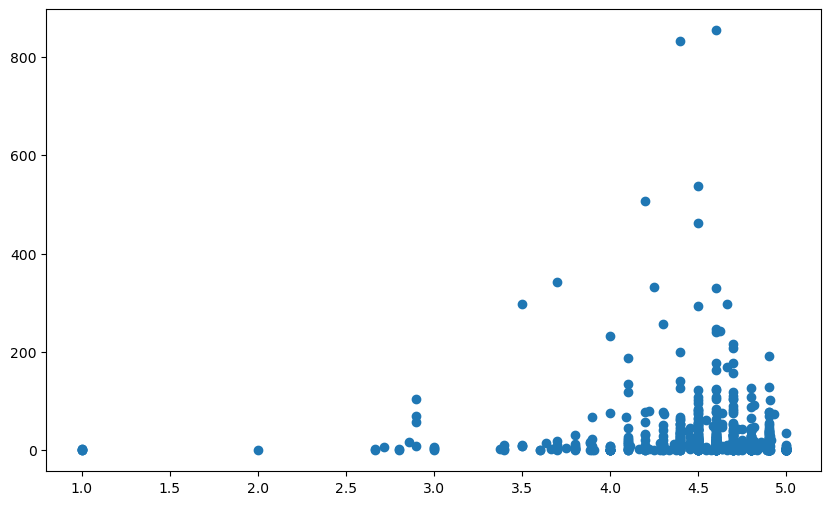

In [47]:
from scipy import stats

# Data column extraction
aval = df00['avg_rating']
prch = df00['total_helpful_votes']

#  Visualie the data
plt.figure(figsize=(10,6))

plt.scatter(aval, prch)

plt.show()

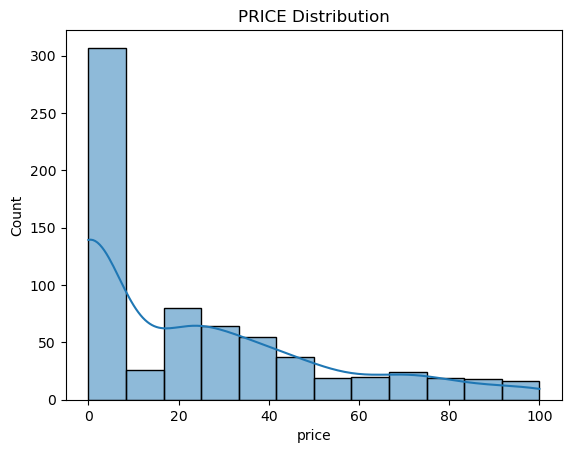

In [48]:
# Histogram for the Price column
df00['price'] = df00['price'].clip(upper=100)
sns.histplot(df00['price'], kde=True) # 'kde' adds a density curve
# plt.xlim(0, 125)  # Maxes out the visual scale at 125
plt.title('PRICE Distribution')
plt.show()

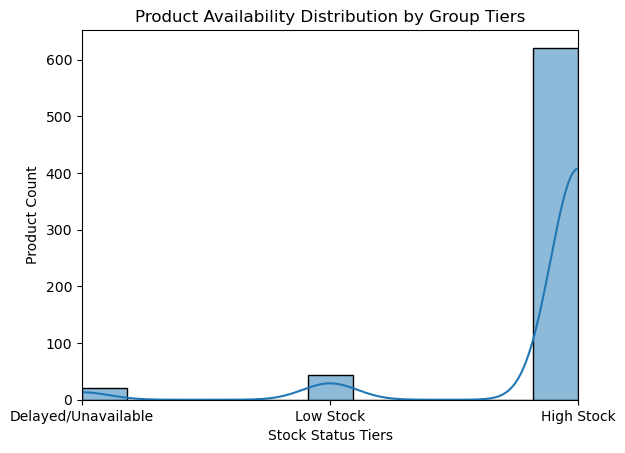

In [49]:

# Histogram for the Price column
sns.histplot(df00['availability_encoded'], kde=True) # 'kde' adds a density curve
plt.xlim(1, 3)  # Maxes out the visual scale at 125
plt.xticks(ticks=[1, 2, 3], labels=['Delayed/Unavailable', 'Low Stock', 'High Stock'])
plt.title('Product Availability Distribution by Group Tiers')
plt.xlabel('Stock Status Tiers')
plt.ylabel('Product Count')
plt.show()



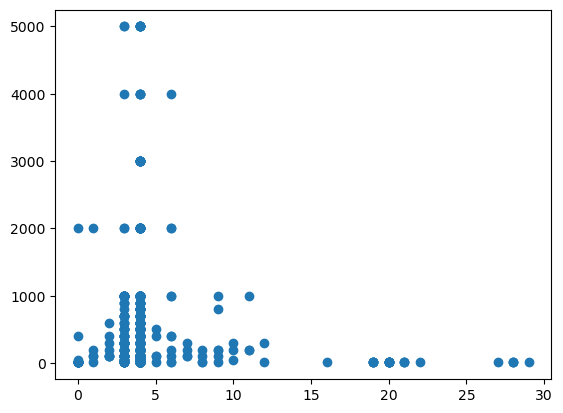

In [50]:
# 'availability', 'default_variant/0', 'price', 'value', 'delivery_time', 'number_of_clicks', 
# 'img_cont', 'cont_rating', 'total_helpful_votes'
# 'avg_rating', 'avg_sentiment',
# 'purchaseCount',  'total_reviews', 
# Histogram for the Price column

df00['cont_rating'] = df00['cont_rating'].clip(upper=100000)
df00['purchaseCount'] = df00['purchaseCount'].clip(upper=5000)

x = df00['delivery_time']
y = df00['purchaseCount']

# plt.xlim(0, 125)  # Maxes out the visual scale at 125


plt.scatter(x, y)

<Axes: xlabel='CCV_Score', ylabel='Count'>

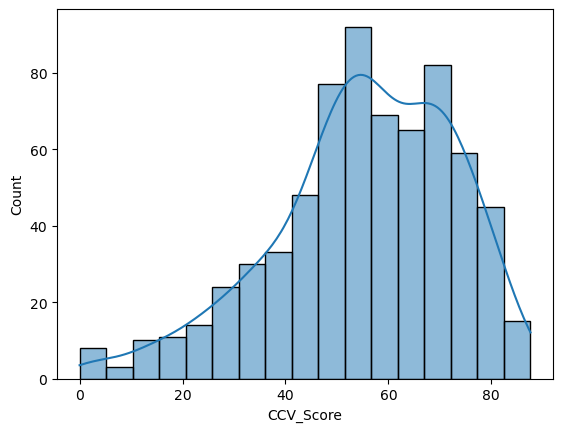

In [52]:
df01 = df00.copy()

In [54]:
# Financial Ratios
# Rating, sentiment score, user feedback influence towards the purchase count

from sklearn.preprocessing import MinMaxScaler

# 2. Initialize the Scikit-Learn Scalers
scaler = MinMaxScaler()
sentiment_scaler = MinMaxScaler(feature_range=(1, 5))

# 3. Transform Review Volume Safely (using double brackets)
df01['ln_cont_rating'] = np.log1p(df00['cont_rating'])
df01['vol_weight'] = scaler.fit_transform(df01[['ln_cont_rating']])

# 4. Transform Sentiment Safely (using double brackets)
df01['sentiment_stars'] = sentiment_scaler.fit_transform(df00[['avg_sentiment']])

# 5. Calculate the Core Quality Component
df01['base_quality_score'] = (df00['avg_rating'] * 0.7) + (df01['sentiment_stars'] * 0.3)

# 6. Generate the Final CCV Score
df01['CCV_Score'] = round(df01['base_quality_score'] * df01['vol_weight'] * 20, 1)

# 7. Print your updated dataframe columns
print(df01[['cont_rating', 'avg_rating', 'avg_sentiment', 'CCV_Score']].head())

   cont_rating  avg_rating  avg_sentiment  CCV_Score
0         1654    4.700000       0.465930       53.9
1         2175    4.700000       0.440964       55.8
2        11355    5.000000       0.269507       70.0
3        13349    4.600000       0.348187       67.8
4         3781    4.727273       0.347863       59.3


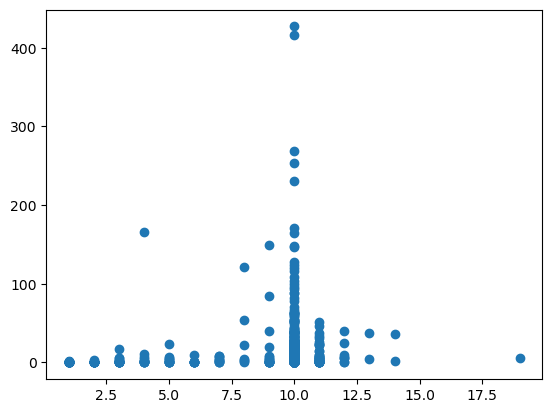

In [81]:



# df01['log_x'] = np.log1p(df01['CCV_Score'])

# plt.figure(figsize=(6, 4))
# sns.scatterplot(data=df01, x='log_x', y='total_reviews')
# plt.title('Log-Transformed Data Spread')
# plt.show()

x = (df01['total_reviews']) *1
y = df01['total_helpful_votes']**1/2

# plt.xlim(0, 125)  # Maxes out the visual scale at 125
plt.scatter(x, y)
# sns.histplot(y, kde=True)

<Axes: xlabel='CCV_Score', ylabel='Count'>

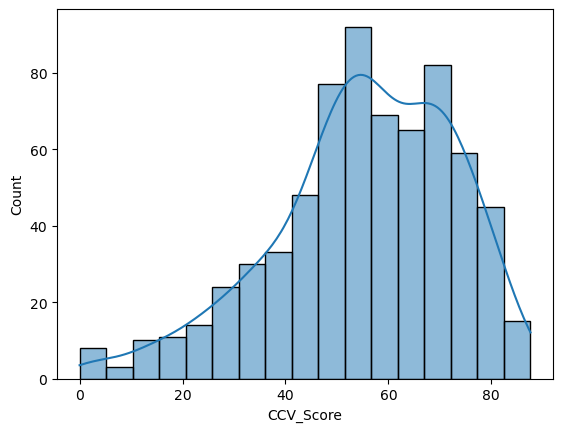

In [82]:
sns.histplot(df01['CCV_Score'], kde=True)

# DAta Ratios


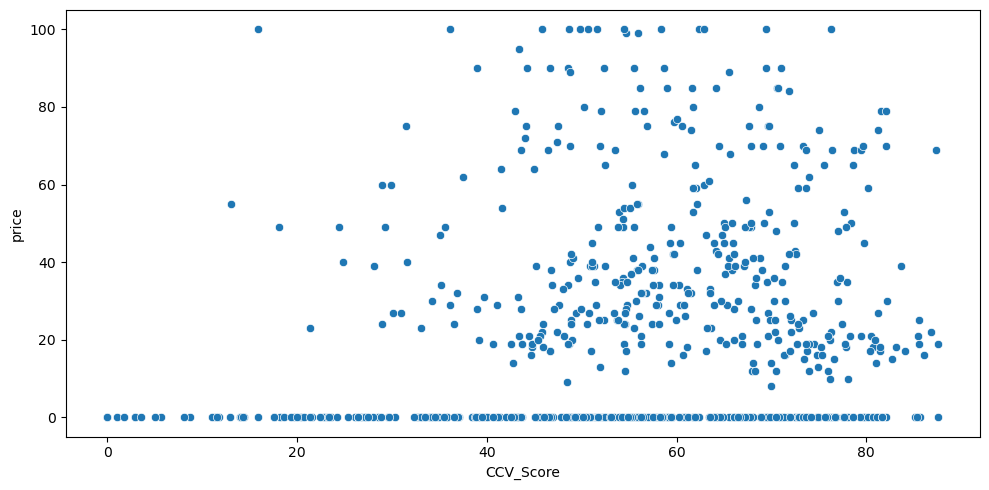

In [330]:
# 'availability', 'default_variant/0', 'price', 'value', 'delivery_time', 'number_of_clicks', 'img_cont', 'cont_rating', 'total_helpful_votes'
# 'avg_rating', 'avg_sentiment',
# 'purchaseCount',  'total_reviews', 

#  For price value '0' price = value of product to avoid loss (assumption)
df00.loc[df00['price'] == 0, 'value'] = 0
# Set up a 1-row, 3-column dashboard comparison
fig= plt.subplots(1, figsize=(10, 5))

ax = sns.scatterplot(data=df01, x='CCV_Score', y='price')

# CRITICAL CLEANUP: Force the X-axis to only show ticks every 5 units (0, 5, 10, 15...)
# ax.xaxis.set_major_locator(ticker.MultipleLocator(5))

# # 3. Jittered Strip Plot (Spreads out the overplotted dots)
# sns.stripplot(data=df01, x='value', y='price')
# # axes.set_title('Option 3: Jittered Strip Plot (Raw Spread)')

plt.tight_layout()
plt.show()

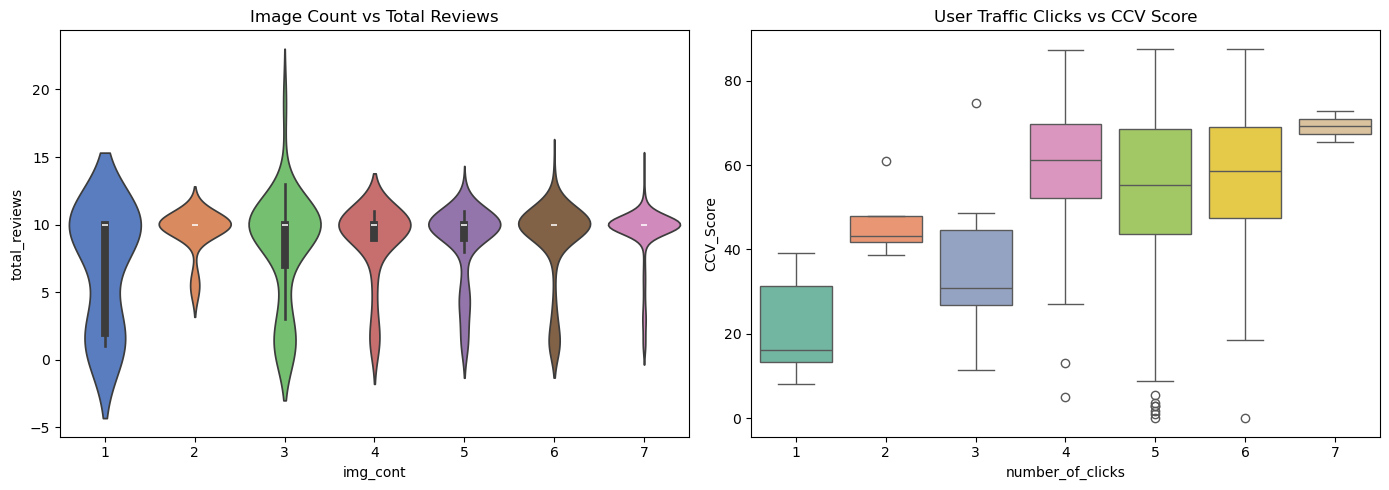

In [85]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set up a 1-row, 2-column dashboard comparison based on your code lines
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Fixed Violin Plot: Assigned hue='img_cont' and disabled the redundant legend
sns.violinplot(
    data=df01, 
    x='img_cont', 
    y='total_reviews', 
    ax=axes[0], 
    palette="muted", 
    hue='img_cont',     # FIX: Assign x variable to hue
    legend=False        # FIX: Remove auto-generated legend box
)
axes[0].set_title('Image Count vs Total Reviews')

# 2. Fixed Box Plot: Assigned hue='number_of_clicks' and disabled the redundant legend
sns.boxplot(
    data=df01, 
    x='number_of_clicks', 
    y='CCV_Score', 
    ax=axes[1], 
    palette="Set2", 
    hue='number_of_clicks', # FIX: Assign x variable to hue
    legend=False            # FIX: Remove auto-generated legend box
)
axes[1].set_title('User Traffic Clicks vs CCV Score')

plt.tight_layout()
plt.show()

# Creates a new column where value becomes 0 only if price is 0
df01['price_'] = df01['price'].mask(df01['price'] == 0, 0)


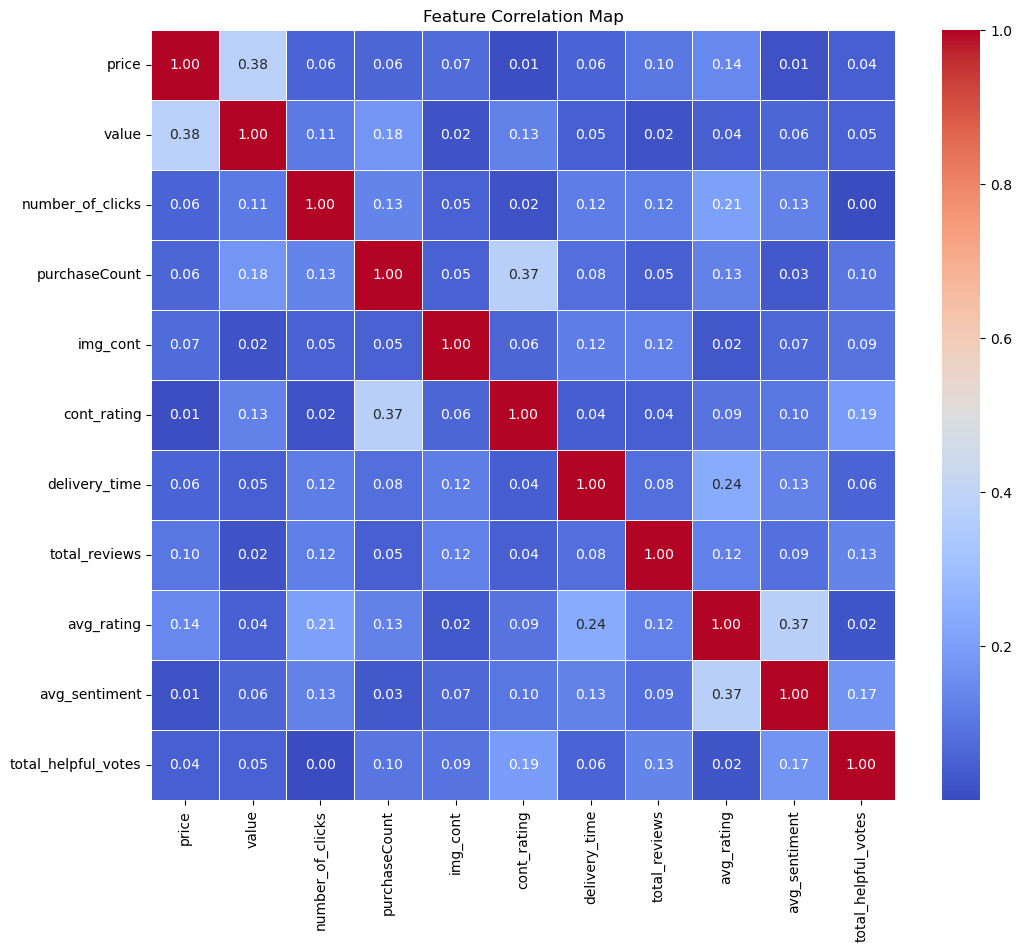

In [86]:
# Create a corelation  matrix
df_enc = pd.get_dummies(df0, columns=[], drop_first=True)

x = df_enc.drop(columns=['availability', 'default_variant/0'])
y = df_enc['purchaseCount']

corr_mat = x.corr().abs()
plt.figure(figsize=(12,10))

sns.heatmap(corr_mat,
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            linewidths=.5)

plt.title('Feature Correlation Map')
plt.show()

In [87]:
# Data Preparation and Modeling

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [88]:

m = len(df01)
print(m)


685


Text(0, 0.5, 'Y')

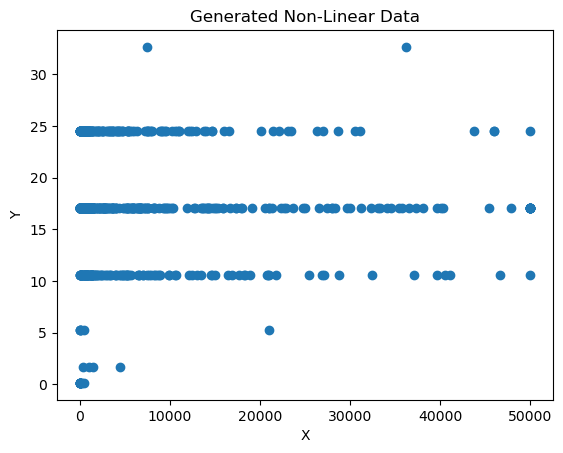

In [329]:
# Seed for reproducibility
np.random.seed(42)
tim = df01['cont_rating']**1/2
rat = df01['purchaseCount']

#  Data points
# m = len(df01)
x = (tim )** 1
y = np.log1p(rat)** 4

# Plot Data
plt.scatter(x,y)
plt.title("Generated Non-Linear Data")
plt.xlabel("X")
plt.ylabel("Y")

In [90]:
# 1. Define your features (X) and target variable (y)
# We drop categorical identifiers and the target variable itself
X = df01[[  'value',  'delivery_time',  'number_of_clicks', 'avg_rating',  'cont_rating','total_helpful_votes']]
y = df01['CCV_Score']

# 2. Split the data into Training (80%) and Testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=63)


In [91]:
# 3. Feature Scaling (Standardization)
# Crucial for linear models so that scale differences don't distort coefficients
scaler = StandardScaler()                         # Define Scaler
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Initialize and train the Linear Regression Model
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# 5. Make predictions on the test set
y_pred = model.predict(X_test_scaled)

# 6. Evaluate model performance
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared (R²) Score: {r2:.2f}")

Root Mean Squared Error (RMSE): 10.34
R-squared (R²) Score: 0.66


In [92]:
from sklearn.preprocessing import PolynomialFeatures

ply_feat = PolynomialFeatures(degree=10, include_bias=False)
X_tr_ply = ply_feat.fit_transform(X_train)
X_ts_ply = ply_feat.transform(X_test)

print(X_tr_ply.shape[1])

# Scale features by putting scaler features in the polynomial FEatures
scl = StandardScaler()
X_tr_scl = scl.fit_transform(X_tr_ply)
X_ts_scl = scl.fit_transform(X_ts_ply)
print(X_tr_scl.shape)
print(X_ts_scl.shape)


8007
(548, 8007)
(137, 8007)


In [93]:
from sklearn.linear_model import LinearRegression,Ridge, Lasso

# Fitting in the RidgeLasso
ridge = Ridge(alpha=1.0)
ridge.fit(X_tr_scl, y_train)

lasso = Lasso(alpha=1.0, max_iter=100000)
lasso.fit(X_tr_scl, y_train)

print(np.sum(ridge.coef_ !=0), len(ridge.coef_))
print(np.sum(lasso.coef_ !=0), len(lasso.coef_))

8007 8007
13 8007


In [94]:
# compute the r2, MSE
# 'availability', 'default_variant/0', 'price', , , 'number_of_clicks', 'img_cont', 'cont_rating', 'total_helpful_votes'
# 'avg_rating', ,
# 'purchaseCount',  'total_reviews', 

def evaluate(name, model):
    p_tr = model.predict(X_tr_scl)
    p_te = model.predict(X_ts_scl)
    return {"Model": name,
            "Train R2": r2_score(y_train, p_tr),
            "Test R2":  r2_score(y_test, p_te),
            "Train MSE": mean_squared_error(y_train, p_tr),
            "Test MSE":  mean_squared_error(y_test, p_te)}

res = pd.DataFrame([evaluate(" ",ridge), evaluate(" ", lasso)])

res.round(4)

,Model,Train R2,Test R2,Train MSE,Test MSE
0,,0.9310,-0.9557,21.5428,617.1596
1,,0.6993,0.6900,93.9407,97.8299


In [95]:
rdg_pred = ridge.predict(X_ts_scl)
lso_pred = lasso.predict(X_ts_scl)

print(f" Ridge -> {r2_score(y_test, rdg_pred):.4f}, MSE: {mean_squared_error(y_test, rdg_pred):.4f}")
print(f" Lasso -> {r2_score(y_test, lso_pred):.4f}, MSE: {mean_squared_error(y_test, lso_pred):.4f}")

 Ridge -> -0.9557, MSE: 617.1596
 Lasso -> 0.6900, MSE: 97.8299


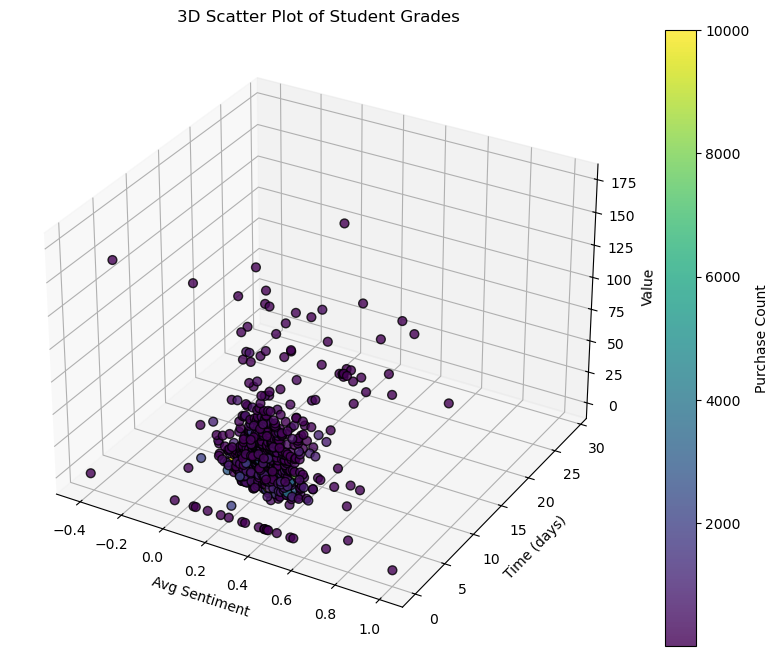

In [112]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot
sc = ax.scatter(df01['avg_sentiment'], df01['delivery_time'], df01['value'], c=df['purchaseCount'], cmap='viridis', s=40, edgecolor='k', alpha=0.8)

# Labels and title
ax.set_xlabel('Avg Sentiment ')
ax.set_ylabel('Time (days)')
ax.set_zlabel('Value')
ax.set_title('3D Scatter Plot of Student Grades')

# Add a color bar
plt.colorbar(sc, label='Purchase Count')
plt.show()

Clustering completed successfully! Cluster breakdown:
Cluster
1    562
0    119
2      4
Name: count, dtype: int64


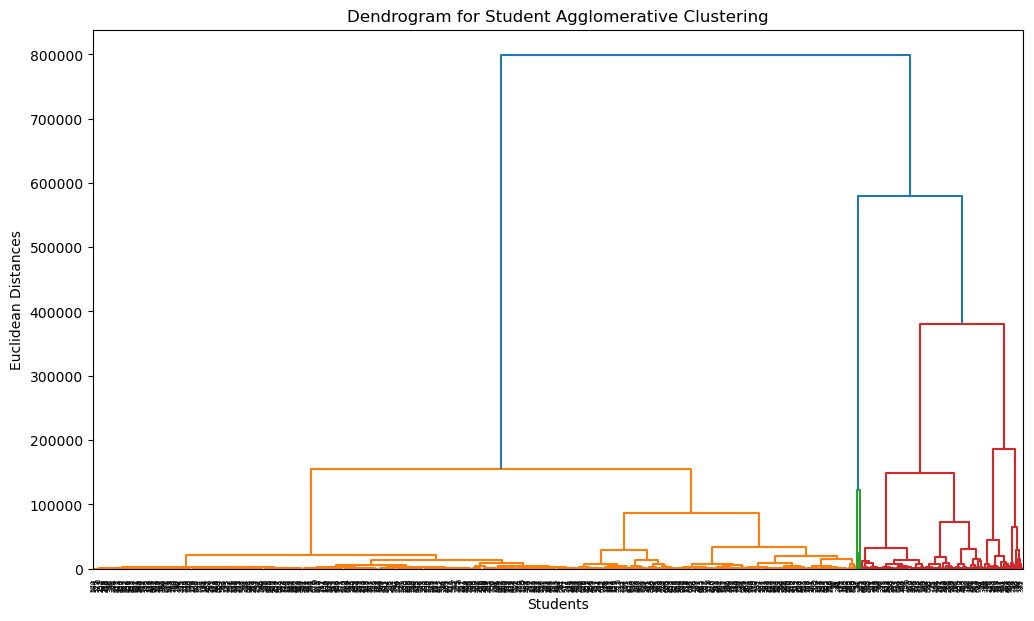

Clustering completed successfully! Cluster breakdown:
Cluster
1    562
0    119
2      4
Name: count, dtype: int64


In [137]:
# Create clusters using agglomerative Clustering
import scipy.cluster.hierarchy as sch
from sklearn.cluster import AgglomerativeClustering



# 1. Plot a Dendrogram to find the ideal number of clusters
plt.figure(figsize=(12, 7))
plt.title('Dendrogram for Student Agglomerative Clustering')
plt.xlabel('Students')
plt.ylabel('Euclidean Distances')

# Using Ward's method to minimize variance within clusters
# 1. Clean the dataset: Drop the categorical text columns you excluded earlier
X_clstr = df_enc.drop(columns=['availability', 'default_variant/0'], errors='ignore')

# 2. Fill any remaining hidden NaNs/missing values with 0 so scikit-learn can process it
# (Alternatively, use X_clustering.dropna() if you prefer to discard rows with missing data)
X_clstr = X_clstr.fillna(0)

dendrogram = sch.dendrogram(sch.linkage(X_clstr, method='ward'))
plt.show()

# 2. Fit Agglomerative Clustering
# Look at your dendrogram to pick n_clusters (let's assume 3 based on standard cuts)
n_clusters = 3
hc = AgglomerativeClustering(n_clusters=n_clusters, metric='euclidean', linkage='ward')
cluster_labels = hc.fit_predict(X_clstr)

# 3. Add the cluster labels back to your original DataFrame for analysis
df01['Cluster'] = cluster_labels
df00['Cluster'] = cluster_labels
df_enc['Cluster'] = cluster_labels
df['Cluster'] = cluster_labels

# 4. Add the cluster labels back to your original DataFrame for analysis
df01['Cluster'] = cluster_labels

print("Clustering completed successfully! Cluster breakdown:")
print(df01['Cluster'].value_counts())



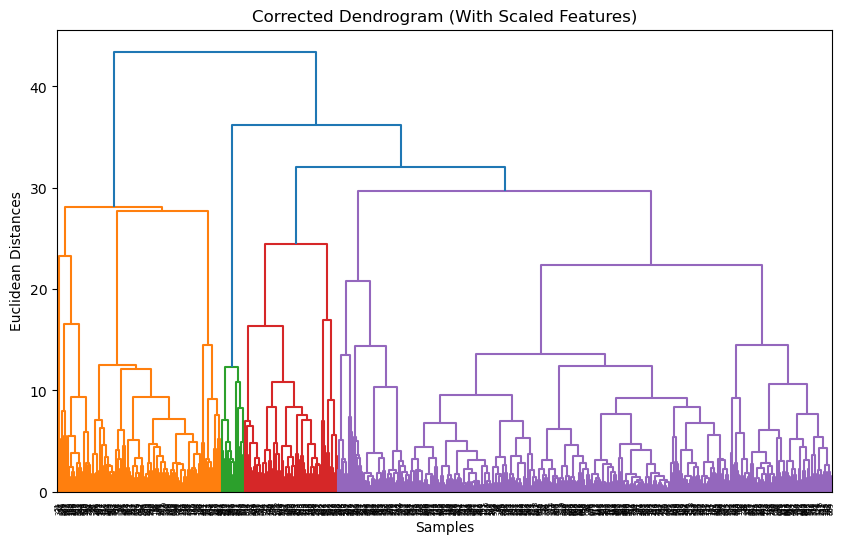

In [113]:
# 1. Drop identifier text columns and make sure everything is numeric
X_clustering = df_enc.drop(columns=['availability', 'default_variant/0'], errors='ignore').fillna(0)

# 2. IMPORTANT STEP: Scale features so all columns have an equal say (Mean=0, Variance=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clustering)

# 3. Plot the NEW, corrected dendrogram
plt.figure(figsize=(10, 6))
# Notice we pass X_scaled instead of the raw dataframe
linkage_matrix = sch.linkage(X_scaled, method='ward')
dendrogram = sch.dendrogram(linkage_matrix)

plt.title('Corrected Dendrogram (With Scaled Features)')
plt.xlabel('Samples')
plt.ylabel('Euclidean Distances')
plt.show()

In [238]:
# 1. Group the original data by the cluster assignments you generated
# 'availability', 'default_variant/0', , , , , 'img_cont', 'cont_rating', 'total_helpful_votes'
# 'avg_rating', ,
# ,  'total_reviews', 
cluster_profile = df01.groupby('Cluster').agg(
    product_count=('purchaseCount', 'count'),
    avg_price=('value', 'mean'),
    avg_list_price=('price', 'mean'),
    avg_rating=('cont_rating', 'mean'),
    num_clicks=('number_of_clicks', 'mean'),
    img_avg = ('img_cont', 'mean')
    # Add any other numeric features you scaled here
).reset_index()

# 2. View the characteristics of each group
print("=== CLUSTER CHARACTERISTICS ===")
print(cluster_profile)

cluster_profile = df.groupby('Cluster').agg(
    product_count=('purchaseCount', 'count'),
    avg_price=('value', 'mean'),
    avg_list_price=('price', 'mean'),
    avg_rating=('avg_rating', 'mean'),
    # Add any other numeric features you scaled here
).reset_index()

# 2. View the characteristics of each group
print("=== CLUSTER CHARACTERISTICS ===")
print(cluster_profile)

# print(df0[[', 'rating_count']].head())
    

=== CLUSTER CHARACTERISTICS ===
   Cluster  product_count  avg_price  avg_list_price    avg_rating  \
0        0            119  25.932773       24.915966  51456.352941   
1        1            562  34.911032       23.343416    4628.52669   
2        2              4  21.250000       11.250000      100000.0   

   num_clicks   img_avg  
0    4.966387  6.075630  
1    4.960854  5.934164  
2    5.000000  6.500000  
=== CLUSTER CHARACTERISTICS ===
   Cluster  product_count  avg_price  avg_list_price  avg_rating
0        0            119  25.932773       24.915966    4.614408
1        1            562  34.911032       24.202847    4.496416
2        2              4  21.250000       11.250000    4.544192


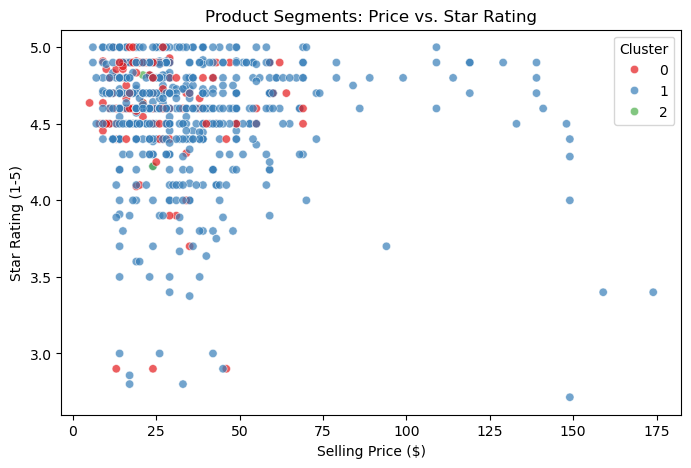

In [239]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df01[(df01['value'] > 0 )& (df01['avg_rating'] >= 2.5)], 
    x='value', 
    y='avg_rating', 
    hue='Cluster', 
    palette='Set1', 
    alpha=0.7
)
plt.title('Product Segments: Price vs. Star Rating')
plt.xlabel('Selling Price ($)')
plt.ylabel('Star Rating (1-5)')
plt.legend(title='Cluster')
plt.show()

In [155]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
# 1. Select your features (X) and target label (y)
# We will use the numeric columns we cleaned earlier
features = ['price', 'value', 'avg_rating', 'delivery_time', '']
X = df00[features].fillna(0)
y = df00['purchaseCount']  # Our target variable (True/False)

# 2. Split into Training (80%) and Testing (20%) datasets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Train a Supervised Classifier
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# 4. Make Predictions on the Test Set
y_pred = model.predict(X_test)

# 5. Output Accuracy and Precision Results
print("================ MODEL PERFORMANCE ================")
print(f"Overall Accuracy Score: {accuracy_score(y_test, y_pred):.4f}\n")
print("Detailed Classification Report (Precision & Recall):")
print(classification_report(y_test, y_pred))

================ MODEL PERFORMANCE ================
Overall Accuracy Score: 0.2044

Detailed Classification Report (Precision & Recall):
              precision    recall  f1-score   support

          10       0.50      0.50      0.50        26
          50       0.17      0.27      0.21        11
         100       0.33      0.33      0.33        21
         200       0.22      0.13      0.17        15
         300       0.00      0.00      0.00        12
         400       0.00      0.00      0.00        10
         500       0.00      0.00      0.00         7
         600       0.00      0.00      0.00         4
         700       0.25      0.25      0.25         4
         800       0.00      0.00      0.00         3
         900       0.00      0.00      0.00         2
        1000       0.11      0.17      0.13        12
        2000       0.00      0.00      0.00         5
        3000       0.00      0.00      0.00         2
        4000       0.00      0.00      0.00         

In [156]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Using the same X, but y is treated as a continuous number
y_continuous = df01['purchaseCount'].fillna(0) 

X_train, X_test, y_train, y_test = train_test_split(X, y_continuous, test_size=0.2, random_state=42)

# 2. Train a Regressor instead of a Classifier
regressor = RandomForestRegressor(random_state=42)
regressor.fit(X_train, y_train)

# 3. Predict and evaluate
y_pred = regressor.predict(X_test)
print(f"Mean Absolute Error (Average off-by amount): {mean_absolute_error(y_test, y_pred):.2f}")
print(f"R-squared Score (Model Fit Accuracy): {r2_score(y_test, y_pred):.4f}")

Mean Absolute Error (Average off-by amount): 466.12
R-squared Score (Model Fit Accuracy): -0.1907


In [224]:
# 'availability', 'default_variant/0', , ,  , 'total_helpful_votes'
# 'avg_rating', ,total_reviews          0

#     0
# 
#
# 1. Feature Engineering: Include text length and sentiment if available
# We calculate review length because longer reviews are statistically more "helpful"
# Select a stronger feature set

features = ['price', 'total_reviews', 'number_of_clicks', 
            'delivery_time',  'total_helpful_votes',
            'value', 'img_cont' , 'availability_encoded', 'purchaseCount']
X = df01[features].fillna(0)

# 2. CRITICAL: Apply Log Transformation to the target variable to neutralize extreme outliers
# np.log1p safely handles 0 values by calculating log(x + 1)
y_raw = df01['CCV_Score'].fillna(0)
y_logged = np.log1p(y_raw)

# 3. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y_logged, test_size=0.2, random_state=42)

# 4. Train the model
regressor = RandomForestRegressor(random_state=64, n_estimators=100)
regressor.fit(X_train, y_train)

# 5. Predict and Reverse the Log Transformation to get real-world metrics
y_pred_logged = regressor.predict(X_test)
y_pred_original = np.expm1(y_pred_logged)  # Reverse log1p
y_test_original = np.expm1(y_test)

# 6. Evaluate the improvements
print("================ RE-ENGINEERED MODEL ================")
print(f"New R-squared Score: {r2_score(y_test, y_pred_logged):.4f}")
print(f"Real-World MAE (Average unit error): {mean_absolute_error(y_test_original, y_pred_original):.2f}")

ValueError: Input X contains infinity or a value too large for dtype('float32').

In [203]:

# 1. Extract the coefficients from your trained Lasso model
# Replace 'X_train' with the name of your feature DataFrame
lasso_coefs = pd.Series(lasso.coef_ , index=lso_pred.columns)

# 2. Separate the winning signals from the dead weight
winning_features = lasso_coefs[lasso_coefs != 0].sort_values(key=abs, ascending=False)
dropped_features = lasso_coefs[lasso_coefs == 0]

print("--- 🏆 GOLDEN PREDICTIVE FEATURES KEPT BY LASSO ---")
print(winning_features)

print("\n--- 🗑️ NOISY FEATURES DROPPED (COEF = 0) ---")
print(dropped_features.index.tolist())





from sklearn.preprocessing import MinMaxScaler

# 1. Load the original dataset sample
data = {
    dfd00['purchaseCount'],
    df00['avg_rating'],
    df00['cont_rating'],
    df['avg_sentiment']
}
df = pd.DataFrame(data)

# 2. Initialize the Scikit-Learn Scaler
scaler = MinMaxScaler()

# Feature 1: Scale review volume (cont_rating) to a 0-1 weight index
# We apply a log transform first so massive outliers don't crush low-volume items
df['log_cont_rating'] = np.log1p(df['cont_rating'])
df['volume_weight'] = scaler.fit_transform(df[['log_cont_rating']])

# Feature 2: Shift and scale avg_sentiment from (-1 to 1) into a (1 to 5) star equivalent
# We pass explicit feature ranges to match standard 5-star constraints
sentiment_scaler = MinMaxScaler(feature_range=(1, 5))
# If your sentiment is already bound strictly between -1 and 1, we clip to ensure safety
df['sentiment_stars'] = sentiment_scaler.fit_transform(df[['avg_sentiment']])

# 3. Calculate Core Component: Base Quality Score (70% Star Rating + 30% Text Sentiment)
df['base_quality_score'] = (df['avg_rating'] * 0.7) + (df['sentiment_stars'] * 0.3)

AttributeError: 'numpy.ndarray' object has no attribute 'columns'

In [ ]:

---------------------------------------------------------------
This Corrected Dendrogram looks phenomenal and is exactly what a healthy, properly scaled hierarchical clustering model should look like!
By applying feature scaling, you have successfully fixed the massive scale bias from before. The Y-axis max distance dropped from 800,000 to around 44, meaning every feature (prices, ratings, sentiment) now has an equal voice in forming these groups.

1. Structural Breakdown & Core Insights

• The Y-Axis (Euclidean Distance): This represents the dissimilarity between groups. The higher up a horizontal line joins two branches, the more distinct and mathematically different those groups are.
• The "Elbow" or Cut-off Threshold: The longest uninterrupted vertical branches occur between a distance of 30 and 43. Imagine drawing a horizontal line across the chart at Y = 30. If you slice through the tree here, it perfectly isolates 3 or 4 major structural clusters.

2. The Formed Clusters (What they mean)

The algorithm has naturally color-coded the data into 4 distinct segments based on their shared attributes:
• Orange Cluster (Far Left): A large, well-defined group. It branches off early from everything else at the highest level (Y ≈ 43), meaning these products have a highly distinct signature compared to all other items in your dataset.
• Green Cluster (Left-Center): A tight, highly compact niche cluster. Because it branches out very low down, the items inside are highly similar to each other.
• Red Cluster (Center): A medium-sized group that joins the green cluster at Y ≈ 36, forming a broader meta-category.
• Purple Cluster (Right): The largest cluster by volume. It forms a massive, expansive web of sub-branches, indicating a highly diverse group of products that still share common underlying feature baselines.

3. Your Next Step in Jupyter Notebook

Now that the clusters make mathematical sense, you need to understand what attributes actually define them (e.g., Is the orange cluster your high-priced items? Is the red cluster your low-rating products?).
Run this cell to profile your clusters and uncover their characteristics:
python
# 1. Group the original data by the cluster assignments you generated
cluster_profile = df01.groupby('Cluster').agg(
    product_count=('productASIN', 'count'),
    avg_price=('price_value_int', 'mean'),
    avg_list_price=('list_price_int', 'mean'),
    avg_rating=('rating_stars', 'mean'),
    # Add any other numeric features you scaled here
).reset_index()

# 2. View the characteristics of each group
print("=== CLUSTER CHARACTERISTICS ===")
print(cluster_profile)
Use code with caution.
Run the code snippet above and share the average price and rating values for each cluster. I can help you translate those numbers into real-world business profiles (like "Premium Products", "Budget Sellers", or "Underperforming Items")!

------------------------------------------------------

Based on these results, you have found exactly what caused the unique layout of your second dendrogram.
Look closely at your avg_rating column. The averages are 51,456, 4,628, and 100,000. On Amazon, star ratings are on a scale of 1 to 5. These massive numbers mean you accidentally passed a column containing raw rating_count (the total number of reviews a product has received) instead of the actual rating_stars (1-5 stars) into your clustering mix.
Because some products have 100,000 reviews and others have only a few thousand, this single variance is still having a heavy impact on your clusters despite scaling.

What Your 3 Clusters Actually Represent:

• Cluster 2 (The 4 Unicorns): These are 4 massive, viral products with exactly 100,000 reviews. They are so unique in terms of volume that they split off entirely as their own mini-group.
• Cluster 0 (The Heavy Hitters): A distinct group of 119 products averaging a massive 51,456 reviews each.
• Cluster 1 (The Bulk Dataset): The remaining 562 products. They have normal, lower review volumes averaging 4,628 reviews.

How to Refine this in Jupyter Notebook

If your goal is to cluster items based on customer satisfaction (1-5 stars) and price, you need to switch the input column from rating_count to your actual star rating column, or drop the total count entirely if it's skewing your business metrics.
Run this quick check to see your exact columns and find the correct star rating field:
python
# Look for a column that has values between 1 and 5 (like 'rating_stars')
print(df01[['rating_stars', 'rating_count']].head())
Use code with caution.
Once you locate the column containing the true 1 to 5 star ratings, would you like the updated code to rerun the scaling pipeline with that column instead?

-------------------------------------------------------------------------------------
Perfect! Now that you have fixed the rating column to show true star ratings (ranging between 4.4 and 4.6), the data reveals real, highly meaningful business segments.
Here is the strategic breakdown of your 3 Product Clusters:

1. Cluster 0: The "High-Value Deals" (119 Products)

• Profile: High-value, discount-oriented items with excellent customer satisfaction.
• Characteristics:
	• The average list price is $24.92, but the selling price is slightly higher at $25.93.
	• This cluster features the highest average rating (4.61) in the entire dataset.
• Business Insight: These items are your top-performing crowd-pleasers. Customers love them, and they are priced very competitively, making them highly reliable revenue drivers.

2. Cluster 1: The "Premium Tier" (562 Products)

• Profile: The core bulk of your catalog, fetching premium price points.
• Characteristics:
	• This is your largest cluster, holding the vast majority of your items.
	• It commands the highest average selling price ($34.91) compared to a lower baseline list price (~$24.20), suggesting these items might include premium variants, bundles, or high-demand products sold by third-party sellers above MSRP.
	• Customer satisfaction remains strong at a 4.50 average rating.
• Business Insight: This is the backbone of your profit margin. These products can support higher pricing strategies without severely degrading customer reviews.

3. Cluster 2: The "Budget/Clearance Exceptions" (4 Products)

• Profile: Deeply discounted budget items.
• Characteristics:
	• A tiny, hyper-specific cluster containing just 4 items.
	• They have the lowest average selling price ($21.25) and an incredibly low list price baseline ($11.25).
	• Their ratings are perfectly healthy at 4.54.
• Business Insight: These are outlier clearance items or highly specific low-cost accessories. They are priced low but maintain good quality standards.

Recommended Next Step (Visualizing the Segments)

To see how distinctly these groups separate in space, run a simple Scatter Plot in your notebook comparing avg_price against avg_rating, colored by your new clusters:
python
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df01, 
    x='price_value_int', 
    y='rating_stars', 
    hue='Cluster', 
    palette='Set1', 
    alpha=0.7
)
plt.title('Product Segments: Price vs. Star Rating')
plt.xlabel('Selling Price ($)')
plt.ylabel('Star Rating (1-5)')
plt.legend(title='Cluster')
plt.show()
Use code with caution.
Does this segment mapping align with the types of products you expected to find? If you want, we can merge your text sentiment column into this profiling to see which cluster uses the most positive words in its reviews.

-------------------------------------------------------------
This scatter plot reveals two major technical patterns that explain exactly how your data is behaving:

1. The "Zero Price" Wall (The Vertical Line at $0)

Look at the far left edge of your plot where a dense vertical stripe of dots sits perfectly at Selling Price = 0.
• This is a direct side effect of using .fillna(0) earlier on missing price fields.
• All the products that didn't have a price in your raw dataset have been forced to $0. This creates an artificial group of products spanning the entire rating scale (from 1.0 to 5.0 stars) at a zero-dollar value.

2. Overlapping Clusters (Why Red and Blue Mix)

You can see that Cluster 0 (Red) and Cluster 1 (Blue) are heavily blended together in this visual space. They occupy the same price ranges ($15 to $90) and the same rating zones (4.0 to 5.0 stars).
• What this means: Price and Star Rating alone were not the only features that separated these two clusters.
• The Reason: Your clustering algorithm (AgglomerativeClustering) evaluated your entire scaled dataset (df_enc), which included other dimensions like delivery periods, variant counts, or availability text features. This 2D graph only projects two of those dimensions, which is why groups that are cleanly separated in a multi-dimensional space look mixed here.

How to Improve Your Notebook Analytics


Action A: Handle the $0 missing values more realistically

Instead of filling missing prices with 0 (which drags down your averages and skews the graphs), you can fill them with the median price of the dataset, or drop rows missing a price entirely before clustering:
python
# Alternative: Drop rows missing a price completely to clean up the plot
df_cleaned_price = df01[df01['price_value_int'] > 0]
Use code with caution.

Action B: Find out what actually separated Cluster 0 and Cluster 1

Since price and rating look similar on this graph, run a quick code block to compare their delivery metrics or image counts to see where the true variance lies:
python
# Look at other features to see where Cluster 0 and 1 differ
print(df01.groupby('Cluster')[['delivery_period_int', 'helpfulVoteCount']].mean())
Use code with caution.
Would you like to modify your code to remove the $0 placeholder products and rerun the scatter plot, or should we inspect which other columns caused Cluster 0 and Cluster 1 to split?
